# Women Safety Analysis and Safe Route Finder

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
csv_file = r"place_safety_route_combinations_single_safety_values.csv"
places_file = r"nagpur_places.csv"
MAX_DETOUR = 1.5
penalty_list = [8, 5, 3, 2]
BIG = 9999
MAX_SCORE = 19
NAME_MATCH = 0.8
valid_limits = {"Street_Lights": 5, "Crowd": 5, "CCTV": 5, "Police": 2, "Incidents": 50}
police_text = {0: "station too far", 1: "far, but not much", 2: "just near"}
time_slots = {1: "5 AM to 4 PM", 2: "4 PM to 7 PM", 3: "7 PM to 5 AM"}
short_names = {"5 AM to 4 PM": "Day", "4 PM to 7 PM": "Evening", "7 PM to 5 AM": "Night"}
rating_names = {0: "UNSAFE", 1: "Okay", 2: "Good"}
map_colors = {0: "r", 1: "orange", 2: "g"}
SCORE = {}
DETAILS = {}
DIST = {}
GRAPH = {}
ROAD_LIST = []
PLACE_X = {}
PLACE_Y = {}
PLACE_TYPE = {}
place_set = set()
proper_names = []
clean_report = {}

## Loading and cleaning

In [2]:
def load_dicts():
    for x in dataset.index:
        place1 = dataset.loc[x, "From"]
        place2 = dataset.loc[x, "To"]
        slot = dataset.loc[x, "Time"]
        distance = dataset.loc[x, "Distance_km"]
        score = int(dataset.loc[x, "Safety_Score"])
        info = [int(dataset.loc[x, "Street_Lights"]), int(dataset.loc[x, "Crowd"]),
                int(dataset.loc[x, "CCTV"]), int(dataset.loc[x, "Police"]),
                int(dataset.loc[x, "Incidents"])]
        SCORE[(place1, place2, slot)] = score
        SCORE[(place2, place1, slot)] = score
        DETAILS[(place1, place2, slot)] = info
        DETAILS[(place2, place1, slot)] = info
        DIST[(place1, place2)] = distance
        DIST[(place2, place1)] = distance
        if place1 not in GRAPH:
            GRAPH[place1] = {}
        if place2 not in GRAPH:
            GRAPH[place2] = {}
        GRAPH[place1][place2] = distance
        GRAPH[place2][place1] = distance
        if slot == time_slots[1]:
            ROAD_LIST.append((place1, place2))
        place_set.add(place1)
        place_set.add(place2)

def load_places():
    for x in places.index:
        name = places.loc[x, "Place"]
        PLACE_X[name] = places.loc[x, "Longitude"]
        PLACE_Y[name] = places.loc[x, "Latitude"]
        PLACE_TYPE[name] = places.loc[x, "Type"]
        proper_names.append(name)

In [3]:
def letters_only(text):
    result = ""
    for ch in str(text).casefold():
        if ch.isalpha():
            result = result + ch
    return result

def lcs_length(text1, text2):
    table = []
    for i in range(len(text1) + 1):
        row = []
        for j in range(len(text2) + 1):
            row.append(0)
        table.append(row)
    for i in range(1, len(text1) + 1):
        for j in range(1, len(text2) + 1):
            if text1[i - 1] == text2[j - 1]:
                table[i][j] = table[i - 1][j - 1] + 1
            else:
                table[i][j] = max(table[i - 1][j], table[i][j - 1])
    return table[len(text1)][len(text2)]

def similarity(text1, text2):
    return 2 * lcs_length(text1, text2) / (len(text1) + len(text2))

def differs(value1, value2):
    if value1 == value2:
        return 0
    else:
        return 1

def clean_name(text):
    typed = letters_only(text)
    best_name = ""
    best_score = 0
    for proper in proper_names:
        score = similarity(typed, letters_only(proper))
        if score > best_score:
            best_score = score
            best_name = proper
    if best_score >= NAME_MATCH:
        return best_name
    else:
        return ""

In [4]:
def start_hour(text):
    text = str(text).upper().replace("-", " TO ")
    parts = text.split("TO")
    first = parts[0].strip()
    digits = ""
    for ch in first:
        if ch.isdigit():
            digits = digits + ch
    if digits == "":
        return -1
    hour = int(digits)
    if ("PM" in first) and (hour < 12):
        hour = hour + 12
    if ("AM" in first) and (hour == 12):
        hour = 0
    if hour > 23:
        return -1
    return hour

def time_bracket(text):
    hour = start_hour(text)
    if hour < 0:
        return ""
    elif (hour >= 5) and (hour < 16):
        return time_slots[1]
    elif (hour >= 16) and (hour < 19):
        return time_slots[2]
    else:
        return time_slots[3]

In [5]:
def clean_data():
    for key in ["names_fixed", "times_fixed", "swapped", "removed", "duplicates",
                "blank_cells", "invalid", "filled", "slot_ok"]:
        clean_report[key] = 0
    clean_report["rows_before"] = len(dataset)
    clean_report["name_spellings"] = len(set(dataset["From"]) | set(dataset["To"]))
    clean_report["time_texts"] = len(set(dataset["Time"]))
    for x in dataset.index:
        first = clean_name(dataset.loc[x, "From"])
        second = clean_name(dataset.loc[x, "To"])
        slot = time_bracket(dataset.loc[x, "Time"])
        if (first == "") or (second == "") or (slot == ""):
            dataset.drop(x, inplace=True)
            clean_report["removed"] = clean_report["removed"] + 1
        else:
            clean_report["names_fixed"] = clean_report["names_fixed"] + differs(first, dataset.loc[x, "From"]) + differs(second, dataset.loc[x, "To"])
            clean_report["times_fixed"] = clean_report["times_fixed"] + differs(slot, dataset.loc[x, "Time"])
            if first > second:
                temp = first
                first = second
                second = temp
                clean_report["swapped"] = clean_report["swapped"] + 1
            dataset.loc[x, "From"] = first
            dataset.loc[x, "To"] = second
            dataset.loc[x, "Time"] = slot
    rows_now = len(dataset)
    dataset.drop_duplicates(subset=["From", "To", "Time"], keep="first", inplace=True)
    clean_report["duplicates"] = rows_now - len(dataset)
    for col in valid_limits:
        clean_report["blank_cells"] = clean_report["blank_cells"] + dataset[col].isnull().sum()
        for x in dataset.index:
            value = dataset.loc[x, col]
            if (value < 0) or (value > valid_limits[col]):
                dataset.loc[x, col] = np.nan
                clean_report["invalid"] = clean_report["invalid"] + 1
    for col in valid_limits:
        for number in time_slots:
            slot = time_slots[number]
            middle = dataset[dataset["Time"] == slot][col].median()
            fill_value = int(middle + 0.5)
            for x in dataset.index:
                if pd.isnull(dataset.loc[x, col]) and (dataset.loc[x, "Time"] == slot):
                    dataset.loc[x, col] = fill_value
                    clean_report["filled"] = clean_report["filled"] + 1
    for col in valid_limits:
        dataset[col] = dataset[col].apply(lambda x: int(x))
    first_count = len(dataset[dataset["Time"] == time_slots[1]])
    clean_report["slot_ok"] = 1
    for number in time_slots:
        slot_count = len(dataset[dataset["Time"] == time_slots[number]])
        if (slot_count < first_count) or (slot_count > first_count):
            clean_report["slot_ok"] = 0

In [6]:
def show_cleaning_report():
    print("")
    print("----- DATA CLEANING REPORT -----")
    print("Rows in the raw file                         :", clean_report["rows_before"])
    print("Different spellings of place names found     :", clean_report["name_spellings"], "(real places: " + str(len(proper_names)) + ")")
    print("Different time texts found                   :", clean_report["time_texts"], "(standard slots: " + str(len(time_slots)) + ")")
    print("Place-name cells corrected                   :", clean_report["names_fixed"])
    print("Time texts changed into a standard slot      :", clean_report["times_fixed"])
    print("Roads written in the other direction (fixed) :", clean_report["swapped"])
    print("Duplicate rows removed                       :", clean_report["duplicates"])
    print("Blank cells filled (median of the slot)      :", clean_report["blank_cells"])
    print("Impossible values replaced (median of slot)  :", clean_report["invalid"])
    print("Rows removed (name or time not understood)   :", clean_report["removed"])
    print("Rows after cleaning                          :", len(dataset))
    if clean_report["slot_ok"] == 0:
        print("WARNING: the time slots do not have the same number of roads!")

## Scoring

In [7]:
def cut2(x):
    return int(x * 100) / 100

def incident_points(incidents):
    if incidents < 5:
        return 2
    elif incidents < 8:
        return 1
    else:
        return 0

def rating_from_score(score):
    if score <= low_cut:
        return 0
    elif score >= high_cut:
        return 2
    else:
        return 1

def prepare_data():
    dataset["Incident_Points"] = 0
    for x in dataset.index:
        dataset.loc[x, "Incident_Points"] = incident_points(dataset.loc[x, "Incidents"])
    dataset["Safety_Score"] = dataset["Street_Lights"] + dataset["Crowd"] + dataset["CCTV"] + dataset["Police"] + dataset["Incident_Points"]

def add_rating_column():
    dataset["Rating"] = 0
    for x in dataset.index:
        dataset.loc[x, "Rating"] = rating_from_score(dataset.loc[x, "Safety_Score"])

## Rankings and charts

In [8]:
def make_matrix(slot):
    size = len(place_names)
    matrix = np.zeros((size, size), dtype=int)
    for key in SCORE:
        place1, place2, key_slot = key
        if key_slot == slot:
            row = place_index[place1]
            col = place_index[place2]
            matrix[row][col] = SCORE[key]
    return matrix

def road_scores(slot):
    scores = []
    for road in ROAD_LIST:
        place1, place2 = road
        scores.append(SCORE[(place1, place2, slot)])
    return np.array(scores)

def ask_slot():
    print("")
    print("Select time of travel:")
    for number in time_slots:
        print("  " + str(number) + ". " + time_slots[number])
    slot_text = input("Enter 1, 2 or 3: ")
    if slot_text.isnumeric() and (int(slot_text) in time_slots):
        return time_slots[int(slot_text)]
    else:
        print("Wrong time slot choice.")
        return ""

In [9]:
def show_rankings():
    slot = ask_slot()
    if slot == "":
        print("Going back to the menu.")
    else:
        slot_df = dataset[dataset["Time"] == slot]
        safest = slot_df.sort_values(by="Safety_Score", ascending=False).head(5)
        print("")
        print("----- TOP 5 SAFEST ROADS (" + slot + ") -----")
        for x in safest.index:
            print("  " + safest.loc[x, "From"] + " - " + safest.loc[x, "To"] + " : " + str(safest.loc[x, "Safety_Score"]) + "/" + str(MAX_SCORE))
        dangerous = slot_df.sort_values(by="Safety_Score", ascending=True).head(5)
        print("")
        print("----- TOP 5 MOST DANGEROUS ROADS (" + slot + ") -----")
        for x in dangerous.index:
            print("  " + dangerous.loc[x, "From"] + " - " + dangerous.loc[x, "To"] + " : " + str(dangerous.loc[x, "Safety_Score"]) + "/" + str(MAX_SCORE))
        matrix = make_matrix(slot)
        place_average = matrix.sum(axis=1) / place_degree
        print("")
        print("----- AVERAGE SAFETY OF EACH PLACE (" + slot + ") -----")
        for i in range(len(place_names)):
            print("  " + place_names[i].ljust(18) + str(cut2(place_average[i])))
        safest_place = place_names[place_average.argmax()]
        risky_place = place_names[place_average.argmin()]
        print("")
        print("Safest place :", safest_place)
        print("Riskiest place (hotspot):", risky_place)

In [10]:
def show_charts():
    slot_labels = []
    slot_averages = []
    for number in time_slots:
        slot = time_slots[number]
        slot_labels.append(short_names[slot])
        slot_averages.append(dataset[dataset["Time"] == slot]["Safety_Score"].mean())
    rating_counts = []
    for r in range(3):
        rating_counts.append(len(dataset[dataset["Rating"] == r]))
    rating_labels = ["Unsafe", "Okay", "Good"]
    day_scores = road_scores(time_slots[1])
    night_scores = road_scores(time_slots[3])
    plt.subplot(2, 2, 1)
    plt.bar(slot_labels, slot_averages, color="r")
    plt.title("Average safety score")
    plt.subplot(2, 2, 2)
    plt.pie(rating_counts, labels=rating_labels)
    plt.title("Roads by rating")
    plt.subplot(2, 2, 3)
    plt.hist(dataset["Safety_Score"])
    plt.title("Spread of safety scores")
    plt.subplot(2, 2, 4)
    plt.scatter(day_scores, night_scores, color="blue", alpha=0.4)
    plt.xlabel("Day score")
    plt.ylabel("Night score")
    plt.title("Same road: day vs night")
    plt.suptitle("WOMEN SAFETY DATA ANALYSIS")
    plt.subplots_adjust(hspace=0.6, wspace=0.5)
    plt.show()

## Map

In [11]:
def draw_map(slot, route):
    for road in ROAD_LIST:
        place1, place2 = road
        road_x = [PLACE_X[place1], PLACE_X[place2]]
        road_y = [PLACE_Y[place1], PLACE_Y[place2]]
        rating = rating_from_score(SCORE[(place1, place2, slot)])
        plt.plot(road_x, road_y, color=map_colors[rating])
    if len(route) > 0:
        route_x = []
        route_y = []
        for name in route:
            route_x.append(PLACE_X[name])
            route_y.append(PLACE_Y[name])
        plt.plot(route_x, route_y, marker='o', ms=10, mec='k', mfc='yellow', color="blue")
    dot_x = []
    dot_y = []
    for name in place_names:
        dot_x.append(PLACE_X[name])
        dot_y.append(PLACE_Y[name])
    plt.scatter(dot_x, dot_y, color="blue")
    for name in place_names:
        plt.text(PLACE_X[name] + 0.002, PLACE_Y[name] + 0.001, name, fontsize=8)
    plt.title("Safety map of Nagpur areas (" + slot + ")")
    plt.xlabel("Red road = unsafe, orange = okay, green = good, blue line = your route")
    plt.ylabel("Latitude (up = north)")
    plt.show()

def show_map():
    slot = ask_slot()
    if slot == "":
        print("Going back to the menu.")
    else:
        print("")
        print("----- NEIGHBOURS OF EVERY PLACE (distance in km) -----")
        for name in place_names:
            line = ""
            for neighbour in sorted(GRAPH[name]):
                line = line + neighbour + " (" + str(GRAPH[name][neighbour]) + ")  "
            print(name.ljust(18) + line)
        draw_map(slot, [])

## Route finder 

In [12]:
def cut1(x):
    return int(x * 10 + 0.5) / 10

def ask_place(question):
    print("")
    print(question)
    for i in range(len(place_names)):
        print("  " + str(i + 1).rjust(2) + ". " + place_names[i].ljust(18) + PLACE_TYPE[place_names[i]])
    place_text = input("Enter the place number: ")
    if place_text.isnumeric() and (int(place_text) >= 1) and (int(place_text) <= len(place_names)):
        return place_names[int(place_text) - 1]
    else:
        print("Wrong place number.")
        return ""

In [13]:
def road_cost(place1, place2, slot, penalty):
    distance = DIST[(place1, place2)]
    if penalty == 1:
        return distance
    rating = rating_from_score(SCORE[(place1, place2, slot)])
    if rating == 0:
        return distance * penalty
    elif rating == 1:
        return distance * 1.15
    else:
        return distance

def find_route(start, end, slot, penalty):
    cost = {}
    came_from = {}
    done = set()
    for name in place_names:
        cost[name] = BIG
    cost[start] = 0
    for turn in range(len(place_names)):
        current = ""
        current_cost = BIG
        found_one = 0
        for name in place_names:
            if (name not in done) and (cost[name] < current_cost):
                current = name
                current_cost = cost[name]
                found_one = 1
        if found_one == 1:
            done.add(current)
            for neighbour in GRAPH[current]:
                new_cost = cost[current] + road_cost(current, neighbour, slot, penalty)
                if new_cost < cost[neighbour]:
                    cost[neighbour] = new_cost
                    came_from[neighbour] = current
    path = [end]
    here = end
    for turn in range(len(place_names)):
        if here in came_from:
            here = came_from[here]
            path.append(here)
    path.reverse()
    return path

In [14]:
def route_km(path):
    total = 0
    for i in range(len(path) - 1):
        total = total + DIST[(path[i], path[i + 1])]
    return cut1(total)

def unsafe_roads(path, slot):
    bad = []
    for i in range(len(path) - 1):
        if rating_from_score(SCORE[(path[i], path[i + 1], slot)]) == 0:
            bad.append((path[i], path[i + 1]))
    return bad

def route_text(path):
    text = ""
    for i in range(len(path)):
        text = text + path[i]
        if i < len(path) - 1:
            text = text + " -> "
    return text

def show_route(title, path, slot):
    print("")
    print(title)
    print("  Route:", route_text(path))
    for i in range(len(path) - 1):
        score = SCORE[(path[i], path[i + 1], slot)]
        rating = rating_from_score(score)
        print("   " + path[i] + " to " + path[i + 1] + " : " + str(DIST[(path[i], path[i + 1])]) + " km, score " + str(score) + "/" + str(MAX_SCORE) + " -> " + rating_names[rating])
    print("  Total distance:", route_km(path), "km")
    print("  Unsafe roads on this route:", len(unsafe_roads(path, slot)))

def explain_road(place1, place2, slot):
    info = DETAILS[(place1, place2, slot)]
    print("   * " + place1 + " to " + place2 + " (" + str(DIST[(place1, place2)]) + " km):")
    print("       Street lights (0-5):", info[0], "(0 = no lights, 5 = best lit)")
    print("       Crowd         (0-5):", info[1], "(0 = empty road, 5 = busiest)")
    print("       CCTV          (0-5):", info[2], "(0 = no CCTV, 5 = high quality)")
    print("       Police        (0-2):", info[3], "(" + police_text[info[3]] + ")")
    print("       Incidents          :", info[4])

In [15]:
def run_route_finder():
    start = ask_place("Select START location:")
    if start == "":
        print("Going back to the menu.")
    else:
        end = ask_place("Select DESTINATION:")
        if end == "":
            print("Going back to the menu.")
        elif start == end:
            print("Start and destination are the same place!")
        else:
            slot = ask_slot()
            if slot == "":
                print("Going back to the menu.")
            else:
                shortest_path = find_route(start, end, slot, 1)
                show_route("SHORTEST ROUTE", shortest_path, slot)
                bad_roads = unsafe_roads(shortest_path, slot)
                final_path = shortest_path
                if len(bad_roads) == 0:
                    print("")
                    print("The shortest route is SAFE. Have a safe journey!")
                else:
                    print("")
                    print("WARNING: The shortest route uses UNSAFE road(s) at this time!")
                    print("Reason:")
                    for road in bad_roads:
                        explain_road(road[0], road[1], slot)
                    limit_km = cut1(route_km(shortest_path) * MAX_DETOUR)
                    print("")
                    print("Looking for a safer route (at most " + str(int((MAX_DETOUR - 1) * 100)) + "% longer, so up to " + str(limit_km) + " km)...")
                    found = 0
                    for penalty in penalty_list:
                        if found == 0:
                            trial = find_route(start, end, slot, penalty)
                            if (route_km(trial) <= limit_km) and (len(unsafe_roads(trial, slot)) < len(bad_roads)):
                                final_path = trial
                                found = 1
                    if found == 1:
                        show_route("SAFER ROUTE", final_path, slot)
                        extra = cut1(route_km(final_path) - route_km(shortest_path))
                        print("")
                        print("Extra distance compared with the shortest route:", extra, "km")
                        if len(unsafe_roads(final_path, slot)) == 0:
                            print("This route avoids all unsafe roads. Have a safe journey!")
                        else:
                            print("This is the safest practical route, but some part is still unsafe.")
                            print("Please travel with someone or share your live location.")
                    else:
                        print("")
                        print("No safer route found within that distance, so the shortest route is shown.")
                        print("Please stay alert, travel with someone or share your live location.")
                map_answer = input("Show this route on the map? (y/n): ").strip().casefold()
                if map_answer == "y":
                    draw_map(slot, final_path)

## Menu and integration

In [16]:
data_ready = False
if os.path.exists(csv_file) and os.path.exists(places_file):
    dataset = pd.read_csv(csv_file)
    raw_data = pd.read_csv(csv_file)
    places = pd.read_csv(places_file)
    load_places()
    clean_data()
    prepare_data()
    low_cut = np.percentile(dataset["Safety_Score"], 25)
    high_cut = np.percentile(dataset["Safety_Score"], 75)
    add_rating_column()
    load_dicts()
    place_names = sorted(place_set)
    place_index = {}
    for i in range(len(place_names)):
        place_index[place_names[i]] = i
    degree_list = []
    for name in place_names:
        degree_list.append(len(GRAPH[name]))
    place_degree = np.array(degree_list)
    sns.set(rc={"figure.figsize": (10, 10)})
    data_ready = True
else:
    print("File not found. Keep these two files in the same folder as this notebook:")
    print("  ", csv_file)
    print("  ", places_file)

In [17]:
def run_menu():
    print("===== WOMEN SAFETY ANALYSIS AND ROUTE FINDER =====")
    show_cleaning_report()
    running = 1
    for turn in range(1000):
        if running == 1:
            print("")
            print("---------------- MENU ----------------")
            print("1. Safest / most dangerous roads and places")
            print("2. Charts")
            print("3. Map of the places (graph)")
            print("4. Find a safe route")
            print("5. Exit")
            choice_text = input("Enter your choice: ")
            if choice_text.isnumeric():
                choice = int(choice_text)
            else:
                choice = 0
            if choice == 1:
                show_rankings()
            elif choice == 2:
                show_charts()
            elif choice == 3:
                show_map()
            elif choice == 4:
                run_route_finder()
            elif choice == 5:
                running = 0
                print("Stay safe! Bye.")
            else:
                print("Wrong choice, please enter a number from 1 to 5.")

===== WOMEN SAFETY ANALYSIS AND ROUTE FINDER =====

----- DATA CLEANING REPORT -----
Rows in the raw file                         : 156
Different spellings of place names found     : 92 (real places: 23)
Different time texts found                   : 34 (standard slots: 3)
Place-name cells corrected                   : 70
Time texts changed into a standard slot      : 100
Roads written in the other direction (fixed) : 17
Duplicate rows removed                       : 9
Blank cells filled (median of the slot)      : 16
Impossible values replaced (median of slot)  : 4
Rows removed (name or time not understood)   : 0
Rows after cleaning                          : 147

---------------- MENU ----------------
1. Safest / most dangerous roads and places
2. Charts
3. Map of the places (graph)
4. Find a safe route
5. Exit


Enter your choice:  1



Select time of travel:
  1. 5 AM to 4 PM
  2. 4 PM to 7 PM
  3. 7 PM to 5 AM


Enter 1, 2 or 3:  2



----- TOP 5 SAFEST ROADS (4 PM to 7 PM) -----
  Civil Lines - Sitabuldi : 17/19
  Dhantoli - Ramdaspeth : 17/19
  Dhantoli - Dharampeth : 17/19
  Ramdaspeth - Sitabuldi : 16/19
  Bajaj Nagar - Trimurti Nagar : 16/19

----- TOP 5 MOST DANGEROUS ROADS (4 PM to 7 PM) -----
  Gittikhadan - Kamptee : 6/19
  Koradi - Koradi Road : 7/19
  Hingna - Trimurti Nagar : 7/19
  Gorewada Area - Koradi Road : 7/19
  Gorewada Area - Seminary Hills : 7/19

----- AVERAGE SAFETY OF EACH PLACE (4 PM to 7 PM) -----
  Bajaj Nagar       13.5
  Besa / Beltarodi  10.33
  Civil Lines       13.8
  Dhantoli          15.5
  Dharampeth        15.6
  Futala            12.25
  Gittikhadan       10.8
  Gorewada Area     8.25
  Hingna            9.66
  Itwari            11.75
  Kamptee           8.33
  Koradi            9.0
  Koradi Road       10.0
  Manewada          10.33
  Manish Nagar      10.8
  Narendra Nagar    12.4
  Pratap Nagar      13.6
  Ramdaspeth        15.0
  Seminary Hills    10.0
  Shankar Nagar     13

Enter your choice:  2


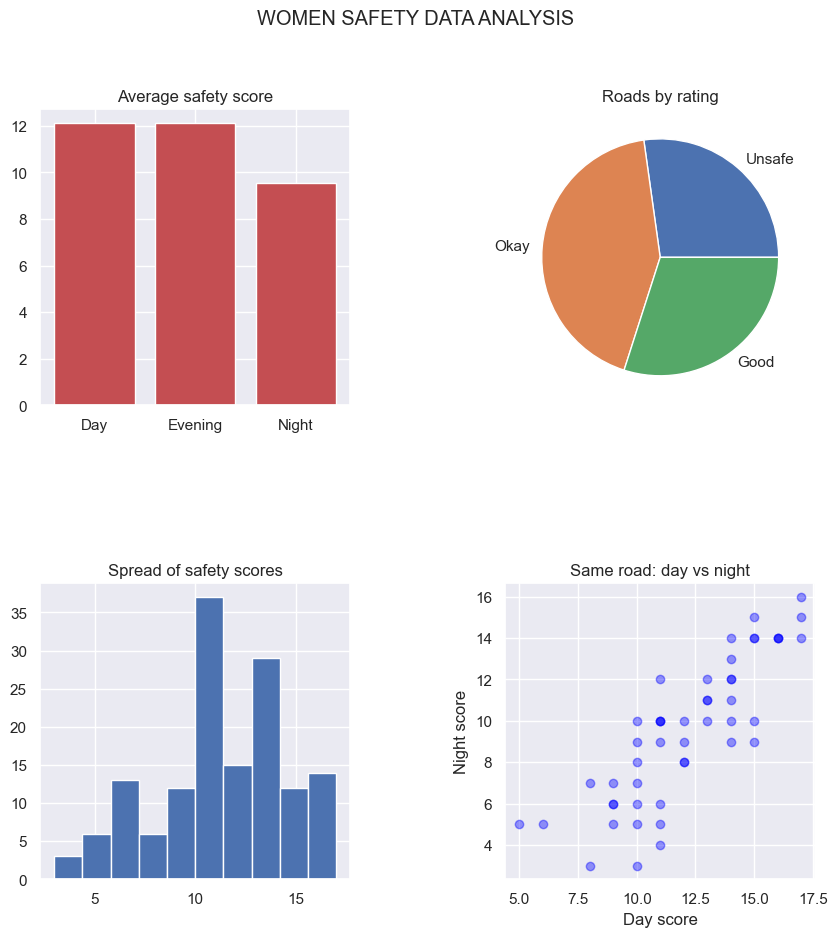


---------------- MENU ----------------
1. Safest / most dangerous roads and places
2. Charts
3. Map of the places (graph)
4. Find a safe route
5. Exit


Enter your choice:  3



Select time of travel:
  1. 5 AM to 4 PM
  2. 4 PM to 7 PM
  3. 7 PM to 5 AM


Enter 1, 2 or 3:  2



----- NEIGHBOURS OF EVERY PLACE (distance in km) -----
Bajaj Nagar       Hingna (8.9)  Pratap Nagar (2.1)  Shankar Nagar (1.2)  Trimurti Nagar (0.9)  
Besa / Beltarodi  Manewada (5.4)  Manish Nagar (6.1)  Narendra Nagar (4.5)  
Civil Lines       Gittikhadan (3.4)  Koradi Road (4.4)  Ramdaspeth (2.9)  Seminary Hills (2.2)  Sitabuldi (2.0)  
Dhantoli          Dharampeth (2.0)  Itwari (3.7)  Ramdaspeth (1.2)  Sitabuldi (1.9)  
Dharampeth        Dhantoli (2.0)  Futala (4.0)  Ramdaspeth (1.3)  Shankar Nagar (1.0)  Trimurti Nagar (1.9)  
Futala            Dharampeth (4.0)  Gorewada Area (5.7)  Seminary Hills (2.5)  Shankar Nagar (3.8)  
Gittikhadan       Civil Lines (3.4)  Kamptee (14.9)  Koradi (10.8)  Koradi Road (2.7)  Sitabuldi (4.5)  
Gorewada Area     Futala (5.7)  Koradi (9.6)  Koradi Road (4.8)  Seminary Hills (5.1)  
Hingna            Bajaj Nagar (8.9)  Manish Nagar (9.3)  Trimurti Nagar (9.5)  
Itwari            Dhantoli (3.7)  Manewada (5.1)  Ramdaspeth (4.3)  Sitabuldi (3.3)  
K

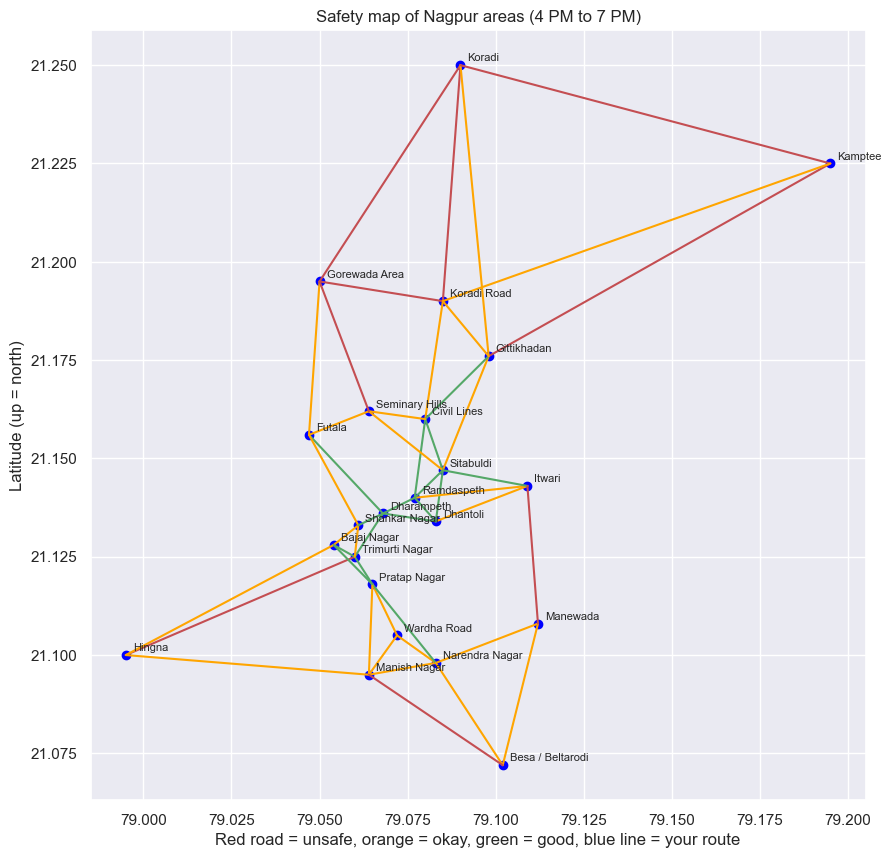


---------------- MENU ----------------
1. Safest / most dangerous roads and places
2. Charts
3. Map of the places (graph)
4. Find a safe route
5. Exit


In [ ]:
run_menu()